In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Positional Information

The sentences "dog bites man" and "man bites dog" contain the same three
tokens. Fed to the self-attention layer of
that section, they produce the same three output
vectors, only listed in a different order. Each output averages value
vectors with weights computed from content alone, and nothing in that
computation records where a token stands. A classifier that pools these
outputs cannot tell who bit whom. Attention must therefore be told where
each token stands.

There are several ways to do so. Absolute embeddings, designed or learned,
add a position vector to each token. Rotary embeddings (RoPE) rotate queries
and keys so that every score depends on the offset between two positions.
Linear biases (ALiBi) penalize distant keys, and a causal model can even
work without any explicit encoding (NoPE). All of them work at the sequence
lengths a model was trained on; beyond those lengths they behave very
differently. We first prove the symmetry that has to be broken and build
each scheme. A small attention-only language model, trained at context 128,
then shows what each scheme does at context 512 and how a trained RoPE model
can be stretched to the longer context.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## Permutation Equivariance

Before choosing a remedy, we state the symmetry precisely, since every
scheme in this section is a way of breaking it. Let
$\mathbf{X} \in \mathbb{R}^{n \times d}$ hold a sequence of $n$ token
representations. At evaluation time, with dropout disabled and with no mask
or position-dependent bias, let $f$ be the self-attention layer

$$
f(\mathbf{X}) = \mathrm{softmax}\!\left(\frac{\mathbf{X}\mathbf{W}_q (\mathbf{X}\mathbf{W}_k)^\top}{\sqrt{d}}\right) \mathbf{X}\mathbf{W}_v.
$$

**Proposition (permutation equivariance).** For every permutation matrix
$\boldsymbol{\Pi}$, $\;f(\boldsymbol{\Pi} \mathbf{X}) = \boldsymbol{\Pi}
f(\mathbf{X})$.

**Proof.** The projections act on each row separately, so
$(\boldsymbol{\Pi}\mathbf{X})\mathbf{W} = \boldsymbol{\Pi}(\mathbf{X}\mathbf{W})$
for each of $\mathbf{W}_q, \mathbf{W}_k, \mathbf{W}_v$. The score matrix
becomes $\boldsymbol{\Pi} \mathbf{S} \boldsymbol{\Pi}^\top$, and since softmax
normalizes each row by itself, it commutes with row and column permutations:
$\mathrm{softmax}(\boldsymbol{\Pi} \mathbf{S} \boldsymbol{\Pi}^\top) =
\boldsymbol{\Pi}\, \mathrm{softmax}(\mathbf{S})\, \boldsymbol{\Pi}^\top$.
Multiplying by the permuted values,
$\boldsymbol{\Pi}\, \mathrm{softmax}(\mathbf{S})\, \boldsymbol{\Pi}^\top
\boldsymbol{\Pi} \mathbf{X}\mathbf{W}_v = \boldsymbol{\Pi} f(\mathbf{X})$
because $\boldsymbol{\Pi}^\top \boldsymbol{\Pi} = \mathbf{I}$. Concatenating
heads and applying $\mathbf{W}_o$ row-wise preserves the property, so it
holds for multi-head attention too. $\blacksquare$

Permuting the input applies the same permutation to the output: each token's
output is unchanged except for its row index. Thus the layer does not use a
token's position in the sequence. We check the proposition on the
multi-head layer of that section by shuffling eight
random tokens and comparing the outputs:

In [ ]:
attention = d2l.MultiHeadAttention(num_hiddens=64, num_heads=4)
X = torch.randn(1, 8, 64)
perm = torch.randperm(8)
Y = attention(X, X, X)
Y_perm = attention(X[:, perm], X[:, perm], X[:, perm])
print(f'max |Y[perm] - Y_perm|: {(Y[:, perm] - Y_perm).abs().max():.2e}')

The two outputs differ only by float32 round-off: the shuffled input
produced the shuffled output. Two caveats qualify this result. First,
equivariance is a property of the *layer*. Stacking equivariant layers and
reading out per token leaves the model equivariant, so depth does not help.
Second, the proposition is about unmasked attention. A causal mask singles
out each position by how many predecessors it may see, which breaks the
symmetry. NoPE, near the end of the section, relies on this asymmetry. The
other schemes give each token explicit positional information.

## Absolute Position Embeddings

The original transformer attaches a *position vector* $\mathbf{p}_i \in
\mathbb{R}^d$ to each position $i$ and feeds $\mathbf{x}_i + \mathbf{p}_i$
into the first layer [@Vaswani.Shazeer.Parmar.ea.2017]. Two tokens with
identical embeddings at different positions now enter attention as different
vectors, and the equivariance proof fails at its first step. The two classic
choices of these vectors differ in whether they are designed or learned.

### Sinusoidal Encodings

The designed choice fills row $i$ of $\mathbf{P} \in \mathbb{R}^{n \times d}$
with sines and cosines of geometrically spaced frequencies,

$$
p_{i, 2m} = \sin\left(\frac{i}{10000^{2m/d}}\right), \qquad p_{i, 2m+1} = \cos\left(\frac{i}{10000^{2m/d}}\right).
$$

The design looks arbitrary until we plot it. We implement the table as a
small function and look at four adjacent columns.

In [ ]:
def sinusoidal_encoding(max_len, num_hiddens):
    """The (max_len, num_hiddens) table of sinusoidal position codes."""
    theta = torch.arange(max_len)[:, None] / 10000 ** (
        torch.arange(0, num_hiddens, 2) / num_hiddens)
    return torch.stack([torch.sin(theta), torch.cos(theta)],
                       -1).reshape(max_len, num_hiddens)

P = sinusoidal_encoding(60, 32)
d2l.plot(torch.arange(60), P[:, 6:10].T, xlabel='position',
         figsize=(6, 2.5), legend=[f'column {d}' for d in range(6, 10)])

Adjacent column pairs share a frequency (one sine, one cosine), and the
frequency falls as the column index grows. This is a continuous version of
binary counting. In the binary representations below, the
lowest bit flips every number, the next every two numbers, the next every
four. Fast dimensions distinguish neighboring positions, whereas slow
dimensions distinguish broader regions.

In [4]:
for i in range(8):
    print(f'{i} in binary is {i:>03b}')

0 in binary is 000
1 in binary is 001
2 in binary is 010
3 in binary is 011
4 in binary is 100
5 in binary is 101
6 in binary is 110
7 in binary is 111


The heatmap of the whole table shows the same structure in continuous form.
Each row is a unique multi-frequency fingerprint of its position. Unlike
bits, the values vary smoothly, so nearby positions get nearby encodings.

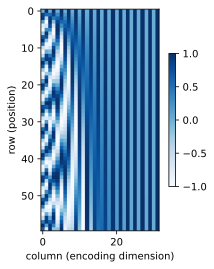

In [5]:
d2l.show_heatmaps(P[None, None], xlabel='column (encoding dimension)',
                  ylabel='row (position)', figsize=(3.5, 4), cmap='Blues')

### Learned Positions

The alternative is to make $\mathbf{P}$ a trainable embedding table, one
free vector per position, as in BERT and GPT-2
[@Devlin.Chang.Lee.ea.2018; @Radford.Wu.Child.ea.2019]. It concedes that
we do not know the right encoding and lets gradient descent find one. Its
limitation is visible before any training. The table has one row for each
position up to some maximum length, and a row that no training example ever
used still holds its random initialization. To such a table, position 500 is
not "a bit beyond position 128". Its row carries no information at all.

### Sinusoidal Encodings as Rotations

Designed sinusoids have a relative-position structure absent from a learned
table. The original paper chose them because, for every fixed offset
$\delta$, the row $\mathbf{p}_{i+\delta}$ is a linear function of the row
$\mathbf{p}_i$. The linear map can be written explicitly. Write
$\omega_m = 1/10000^{2m/d}$ for the frequency shared by columns $2m$ and
$2m{+}1$. Then

$$
\begin{bmatrix} \cos(\delta \omega_m) & \sin(\delta \omega_m) \\  -\sin(\delta \omega_m) & \cos(\delta \omega_m) \\ \end{bmatrix}
\begin{bmatrix} p_{i, 2m} \\  p_{i, 2m+1} \\ \end{bmatrix}
= \begin{bmatrix} \sin\left((i+\delta) \omega_m\right) \\  \cos\left((i+\delta) \omega_m\right) \\ \end{bmatrix}
= \begin{bmatrix} p_{i+\delta, 2m} \\  p_{i+\delta, 2m+1} \\ \end{bmatrix},
$$

by the angle-addition identities. The map from position $i$ to position
$i + \delta$ is a *rotation* of each two-column pair, by an angle $\delta
\omega_m$ that depends only on the offset $\delta$, never on $i$. The
encoding thus contains relative position, but only implicitly. The model
receives $\mathbf{x}_i + \mathbf{p}_i$ and must learn projections
that exploit the rotations. Moreover, a query--key product of two such sums
expands into four terms, and only the position--position term retains the
rotation directly. RoPE instead builds the relative rotation into the
query--key comparison itself.

## Rotary Position Embeddings

*Rotary position embeddings* (RoPE) [@Su.Lu.Pan.ea.2021] skip the
addition and act on queries and keys at the point where they meet, the
score. We want a transformation $\mathbf{R}_i$, applied to the query at
position $i$ and the key at position $j$, such that the score depends only
on the content vectors and the offset $j - i$:

$$
(\mathbf{R}_i \mathbf{q})^\top (\mathbf{R}_j \mathbf{k}) = \mathbf{q}^\top \mathbf{R}_i^\top \mathbf{R}_j \mathbf{k} \overset{!}{=} \mathbf{q}^\top \mathbf{R}_{j-i} \mathbf{k}.
$$

The requirement $\mathbf{R}_i^\top \mathbf{R}_j = \mathbf{R}_{j-i}$ pins down
the kind of map we need. With $i = j$ it reads $\mathbf{R}_i^\top
\mathbf{R}_i = \mathbf{R}_0 = \mathbf{I}$ (position 0 is left as it is),
so every $\mathbf{R}_i$ is orthogonal. With $j = 0$ it gives
$\mathbf{R}_{-i} = \mathbf{R}_i^\top$, and substituting this back yields
$\mathbf{R}_i \mathbf{R}_j = \mathbf{R}_{i+j}$. The $\mathbf{R}_i$ form a
one-parameter group of orthogonal maps, and planar rotations are the
simplest such group. RoPE therefore reuses the sinusoidal frequencies
$\omega_m$, now *multiplicatively*. It splits the $d$ dimensions of each
query into $d/2$ pairs, where $d$ is now the width of one attention head,
and rotates pair $m$ of the query at position $i$ by the angle $i\,\omega_m$
(and likewise for keys),

$$
\mathbf{R}_i = \begin{bmatrix} R(i\omega_0) & & \\ & \ddots & \\ & & R(i\omega_{d/2-1}) \end{bmatrix}, \qquad R(\alpha) = \begin{bmatrix} \cos\alpha & -\sin\alpha \\ \sin\alpha & \cos\alpha \end{bmatrix}.
$$

the figure shows one pair plane. Shifting both positions by
the same amount rotates query and key together, preserving their angle and
their dot product. The score therefore depends on position only through the
offset. Rotations also preserve norms, so RoPE never inflates or shrinks a
token's content. The geometric spacing of the frequencies sets how fast
position turns each pair. The fast pairs separate neighboring positions
sharply, while the slow pairs barely move across a sentence and carry
content largely unchanged. Only queries and keys are rotated; values pass through untouched.
RoPE is the positional scheme of most open-weights language models released
since 2023.

![Rotary embeddings rotate each two-dimensional feature pair of the query and the key by an angle proportional to position. Shifting both positions by the same amount, here by 3, rotates both vectors together and leaves the angle between them ($2\theta + \varphi$ in both panels), and hence the attention score, unchanged. Here $\theta = \omega_m$ is the angle by which pair $m$ turns per position, and $\varphi$ is the angle between the unrotated query and key.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-attention-rope-rotation.svg)

`rope_tables` computes the cosines and sines of the angles, and `rope`
rotates the even/odd feature pairs with them. The argument `offset` shifts
every position by the same amount, which we use to test the invariance. Two
optional arguments change the angles themselves: `base` replaces the
constant $10000$ in the frequencies, and `scale` multiplies the angle of
each pair by its own factor.
Both keep their defaults until that section
stretches a trained model to longer contexts. A caller that rotates many
tensors at the same positions can compute the tables once and pass them to
`rope` as `tables`; cached generation does this in
that section.

In [ ]:
def rope_tables(n, d, offset=0, base=10000.0, scale=None,
                device=None):
    """Cosines and sines, each (n, d/2), of the angles of the positions
    offset, ..., offset + n - 1."""
    pos = torch.arange(n, dtype=torch.float32, device=device) + offset
    omega = base ** (-torch.arange(0, d, 2, device=device) / d)
    if scale is not None:  # One angle factor per pair, shape (d/2,)
        omega = omega * scale
    theta = pos[:, None] * omega[None, :]
    return torch.cos(theta), torch.sin(theta)

def rope(x, offset=0, base=10000.0, scale=None, tables=None):
    """Rotate feature pairs of x (..., num_steps, d) by position angles;
    tables from rope_tables take the place of offset, base, and scale."""
    if tables is None:
        tables = rope_tables(*x.shape[-2:], offset, base, scale, x.device)
    # Angles in fp32, tables in the dtype of x: bf16 queries stay bf16
    cos, sin = (u.to(x.dtype) for u in tables)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin,
                        x1 * sin + x2 * cos], -1).flatten(-2)

To check the equation numerically, we shift all positions jointly;
the full RoPE score matrix should not change. For contrast, we run the
same test on the additive sinusoidal encoding, where the four-term expansion
leaves absolute position in the score.

In [ ]:
T, d = 32, 64
q, k = torch.randn(T, d), torch.randn(T, d)

scores = lambda off: rope(q, off) @ rope(k, off).T / math.sqrt(d)
for off in (1, 17, 480):
    print(f'RoPE, all positions shifted by {off:>3}: max score change '
          f'{(scores(off) - scores(0)).abs().max():.1e}')

P = sinusoidal_encoding(600, d)
added = lambda off: (q + P[off:off+T]) @ (k + P[off:off+T]).T / math.sqrt(d)
print(f'additive sinusoidal, shifted by  17: max score change '
      f'{(added(17) - added(0)).abs().max():.1e}')

At every shift, RoPE's scores change only by float32 round-off, several
orders of magnitude below the scores themselves. This holds even for a
shift far beyond where any additive table would end. The additive encoding,
in contrast, moves the scores by an amount comparable to the scores
themselves. With RoPE, relative position is built into the architecture
rather than learned from data. This property does not guarantee accurate
predictions at offsets absent from the training data; the next experiment
tests such predictions.

## Extrapolation Beyond the Training Length

Every scheme above breaks the permutation symmetry on sequences as long as
those seen in training. The schemes differ on longer ones. A length-extrapolation
test trains at context $L$ and compares perplexity at $L$ with perplexity at,
for example, $4L$. Two more schemes were designed for this setting.

### ALiBi and NoPE

*ALiBi* (attention with linear biases) [@Press.Smith.Lewis.2022]
encodes no positions at all. It instead subtracts a distance penalty from
every attention score. For query position $i$ and key position $j \leq i$
in head $h$ of $H$,

$$
\mathrm{score}_{ij} = \frac{\mathbf{q}_i^\top \mathbf{k}_j}{\sqrt{d}} - m_h\,(i - j), \qquad m_h = 2^{-8h/H}.
$$

Each head discounts distant tokens at its own geometric rate. Head 1 uses a
steep penalty and head $H$ a much smaller one. For $H = 4$ the slopes are
$1/4, 1/16, 1/64, 1/256$. The formula $2^{-8h/H}$ is the paper's choice for
head counts that are powers of two, and the paper gives a separate rule for
other $H$. The bias depends only on distance, so it is defined for every
context length. A distance of 400 is a valid input to the bias, not an
unallocated table index. The drawback is a recency prior built into every
score, which large content scores can offset but training cannot remove.
With slope $1/4$, a key 40 positions back already loses a
factor $e^{-10}$ of its weight, so the steep heads see only a short window
whatever the context length.

*NoPE* (no positional encoding) uses the asymmetry that the proposition
leaves out [@Kazemnejad.Padhi.Ramamurthy.ea.2023]. A causal model can
do without explicit position representations, because the mask already
breaks the symmetry. Position 0 attends over one token, position 100 over a
hundred and one. The number of tokens competing in each softmax is itself
positional information, and a decoder can in principle recover relative
order from it.
Because it uses neither a table nor a rotation, NoPE has no explicit
position range. Its effectiveness depends on how much usable positional
signal the mask supplies.

### An Attention-Only Language Model

To compare extrapolation, we train a deliberately minimal model that the
chapter analyzes again later: a token embedding, a stack of residual
causal attention blocks, and an output head tied to the embedding
[@Press.Wolf.2017]. There is no feed-forward network and no
normalization layer, and the attention projections carry no bias terms by
default (a `bias` switch restores them). Only attention mixes information
across positions, which makes the model easy to analyze in
that section. It is the attention-only cousin of
the `TinyLM` of that section.

The positional scheme is the one constructor argument that the experiment
varies. `pos` takes `'learned'`, `'sinusoidal'`, `'rope'`, `'alibi'`, or
`'none'`, and the constructor allocates what the scheme needs. With RoPE,
the model keeps the base and the per-pair angle factors of `rope` as
attributes, `rope_base` and `rope_scale`, so that they can be changed after
training. The method `stream` runs the residual stream through the blocks
and also returns the attention weights of each block, which
that section inspects.

In [ ]:
class TinyCharLM(nn.Module):
    """Attention-only language model."""
    def __init__(self, vocab_size, num_hiddens=128, num_heads=4, num_blks=2,
                 pos='rope', max_len=512, bias=False):
        super().__init__()
        assert pos in ('learned', 'sinusoidal', 'rope', 'alibi', 'none')
        self.num_heads, self.pos = num_heads, pos
        self.token_emb = nn.Embedding(vocab_size, num_hiddens)
        nn.init.normal_(self.token_emb.weight, std=0.02)
        if pos == 'learned':
            self.pos_emb = nn.Embedding(max_len, num_hiddens)
            nn.init.normal_(self.pos_emb.weight, std=0.02)
        if pos == 'sinusoidal':
            self.register_buffer('P', sinusoidal_encoding(max_len,
                                                          num_hiddens))
        if pos == 'rope':  # Base and per-pair angle factors of the rotation
            self.rope_base = 10000.0
            self.register_buffer('rope_scale',
                                 torch.ones(num_hiddens // num_heads // 2))
        self.blks = nn.ModuleList([nn.ModuleDict(dict(
            qkv=nn.Linear(num_hiddens, 3 * num_hiddens, bias=bias),
            proj=nn.Linear(num_hiddens, num_hiddens, bias=bias)))
            for _ in range(num_blks)])

    def stream(self, X, num_blks=None):
        """Residual stream after the first num_blks blocks (default: all),
        and the attention weights of those blocks."""
        H, maps = self.embed(X), []
        for blk in self.blks[:num_blks]:
            out, weights = self.attend(blk, H)
            H, maps = H + out, maps + [weights]
        return H, maps

    def forward(self, X):
        return F.linear(self.stream(X)[0], self.token_emb.weight)  # Tied

    def attention_weights(self, X):
        """Per-block attention maps, each (batch, num_heads, T, T)."""
        return self.stream(X)[1]

The absolute schemes act once, on the input: `embed` adds the learned or the
sinusoidal table to the token embeddings. With the sinusoidal table, the
token embeddings are multiplied by $\sqrt{d}$ before the table is added, as
in the original transformer. Without this factor the table, whose entries
have magnitude about $0.7$, would outweigh embeddings that start with
entries of about $0.02$ by a factor of 35. With it, the factor is about 3.

In [ ]:
@d2l.add_to_class(TinyCharLM)
def embed(self, X):
    """Token embeddings plus the absolute position code, if any."""
    H = self.token_emb(X)
    if self.pos == 'learned':
        H = H + self.pos_emb(torch.arange(X.shape[1], device=X.device))
    if self.pos == 'sinusoidal':  # Scale tokens up to the table
        H = H * math.sqrt(H.shape[-1]) + self.P[:X.shape[1]]
    return H

The relative schemes act inside every block, on the queries, keys, and
scores. `attend` is causal multi-head attention in which RoPE rotates the
queries and the keys, and ALiBi subtracts the distance penalty of
the equation from the scores. With every other scheme it is plain
causal attention.

In [ ]:
@d2l.add_to_class(TinyCharLM)
def alibi(self, T, device):
    """ALiBi bias -m_h (i - j) of every head, (num_heads, T, T)."""
    h = torch.arange(1, self.num_heads + 1, device=device)
    slopes = 2.0 ** (-8.0 * h / self.num_heads)
    pos = torch.arange(T, device=device, dtype=torch.float32)
    return slopes[:, None, None] * (pos[None, :] - pos[:, None])

@d2l.add_to_class(TinyCharLM)
def attend(self, blk, H):
    """Output of attention block blk on the stream H, and its weights."""
    B, T, D = H.shape
    q, k, v = blk['qkv'](H).chunk(3, -1)
    q, k, v = (u.reshape(B, T, self.num_heads, -1).transpose(1, 2)
               for u in (q, k, v))
    if self.pos == 'rope':
        q = rope(q, base=self.rope_base, scale=self.rope_scale)
        k = rope(k, base=self.rope_base, scale=self.rope_scale)
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if self.pos == 'alibi':
        scores = scores + self.alibi(T, H.device)
    weights = d2l.masked_softmax(scores, d2l.causal_mask(T, device=H.device))
    out = (weights @ v).transpose(1, 2).reshape(B, T, D)
    return blk['proj'](out), weights

### The Experiment

We train one model per scheme on `d2l.WikiText103`, the bytes of Wikipedia
articles that that section introduced. Each model trains at
context length 128 for 3000 steps of `d2l.train_steps`, the fixed-step training
loop of that section. The tokens are bytes, so each model has an embedding
table of 256 rows. The learned and sinusoidal tables are allocated out to
`max_len` $= 512$ positions so that the models can be evaluated on longer
sequences, but only the first 128 rows of the learned table receive
gradients.

In [ ]:
data = d2l.WikiText103(batch_size=64, num_steps=128)
schemes = ('learned', 'sinusoidal', 'rope', 'alibi', 'none')
models = {}
for pos in schemes:
    model = TinyCharLM(len(data.vocab), pos=pos)
    losses = d2l.train_steps(model, data,
                          torch.optim.AdamW(model.parameters(), lr=1e-3,
                                            weight_decay=0.0), 3000)
    models[pos] = model
    print(f'{pos:>10}: final training loss {d2l.final_loss(losses):.2f}')

Every model was trained on length-128 sequences. We evaluate validation
perplexity at that training context, $n = 128$, and at two and four times
this length ($n = 256$ and $512$). The first point is in range; the other
two measure extrapolation. All three read the same 1.1 million bytes of the
validation split. We cut it into consecutive windows of 128 bytes with
`data.windows` and regroup them into windows of 256 and 512, so that only
the context available to each prediction changes. `d2l.lm_perplexity`
(that section) sums the cross-entropy over all predicted tokens and
converts it to a perplexity once at the end.

The table lists the perplexity of each model at the three context lengths.

In [ ]:
train_len, batch = data.num_steps, 16
contexts = (train_len, 2 * train_len, 4 * train_len)
block = batch * max(contexts)  # Whole minibatches at every context
num_bytes = (len(data.val) - 1) // block * block
X, Y = data.windows(data.val, range(0, num_bytes, train_len))
eval_sets = {}
for n in contexts:  # The same bytes, regrouped into windows of n
    Xn, Yn = X.reshape(-1, n), Y.reshape(-1, n)
    eval_sets[n] = [(Xn[i:i + batch], Yn[i:i + batch])
                    for i in range(0, len(Xn), batch)]
ppls = {pos: [d2l.lm_perplexity(models[pos], eval_sets[n]) for n in contexts]
        for pos in schemes}
print(f'{"context":>10}: ' + ''.join(f'{n:>8}' for n in contexts))
for pos in schemes:
    print(f'{pos:>10}: ' + ''.join(f'{p:8.1f}' for p in ppls[pos]))

At the training length, every explicit scheme gives a lower perplexity than
NoPE, and the sinusoidal table and RoPE give the lowest. Beyond the training
length the schemes split into two groups. The learned table, the
sinusoidal table, and RoPE all degrade at context 512, by up to
several-fold, each for its own reason. The learned
table reaches rows beyond position 127 that still hold their random
initialization. The sinusoidal table supplies rows whose slow columns take
values never seen in training. RoPE adds no position vector, but its slow
pairs have periods longer than 128 positions. At offsets beyond 127 they
turn through angles they never reached during training, and the
projections were never fit to scores computed from those angles.

The other two schemes hold their level. ALiBi stays nearly flat because its
bias depends only on distance. NoPE, which has no table and no angles to
run out of, stays flat from a higher starting point. A flat curve, however,
does not mean that a model *uses* the longer context.
ALiBi's steep heads hardly look past the training window at all, as
Exercise 4
measures.

### Extending a Trained Model's Context

Only some of RoPE's pairs meet anything new beyond the training length. A
pair whose period $2\pi/\omega_m$ is at most 128 positions completes a
full turn within the training offsets, so every angle it produces at offset
400 lies within $\omega_m/2$ of an angle it already took during training.
For the head width 32 of `TinyCharLM`, six of the 16 pairs are fast in this
sense, with periods from 6 to 112 positions. The other ten pairs, whose
periods exceed the training length, reach angles at long offsets that they
never took during training. Because the angles vary continuously, they can
be *rescaled* so that the deployed range maps into the trained one.
Multiplying every angle by $128/512$ makes the offset $4\delta$ look like the
familiar $\delta$, so the model interpolates instead of extrapolating.
This is *position interpolation* [@Chen.Wong.Chen.ea.2023], which
extended Llama models from 2,048 to 32,768 tokens with at most 1000
fine-tuning steps.

Uniform rescaling also compresses the fast pairs, which had already seen
every angle, and blurs the angles they use to tell neighbors apart. YaRN
[@Peng.Quesnelle.Fan.ea.2024] therefore interpolates only the slow
pairs, leaves the fast ones as trained, ramps between the two groups, and
adds a softmax temperature. NTK-aware scaling, which the YaRN paper also
describes, reaches a similar split by changing only the base $b = 10^4$.
To grow the context by a factor $s$ (here $s = 4$), it replaces $b$ by
$b' = b\, s^{d/(d-2)}$, which leaves the fastest pair unchanged and divides
the frequency of the slowest pair by exactly $s$. Training with a larger base
from the outset is the trained form of the same idea. Llama 2 Long, for
example, raised the base from $10^4$ to $5 \times 10^5$ in continued
pretraining on long sequences [@Xiong.Liu.Molybog.ea.2024].

The attributes `rope_base` and `rope_scale` of `TinyCharLM` let us try two
of these rescalings on the trained RoPE model without any training: a
uniform factor $128/512$ for all pairs, and the same factor for the slow
pairs only.

In [ ]:
rope_model = models['rope']
d_head = 2 * rope_model.rope_scale.numel()
periods = (2 * math.pi
           * rope_model.rope_base ** (torch.arange(0, d_head, 2) / d_head))
slow = periods > train_len
print(f'{int(slow.sum())} of {d_head // 2} pairs have periods above '
      f'{train_len}')
ones = torch.ones(d_head // 2)
shrink = train_len / max(contexts)  # Longest context into the trained one
factors = {'unscaled': ones, 'all pairs': ones * shrink,
           'slow pairs': torch.where(slow, ones * shrink, ones)}
for name, factor in factors.items():
    rope_model.rope_scale.copy_(factor)
    ppl = [d2l.lm_perplexity(rope_model, eval_sets[n]) for n in contexts]
    print(f'{name:>10}: ' + ''.join(f'{p:8.1f}' for p in ppl))
rope_model.rope_scale.copy_(ones);

Rescaling only the slow pairs brings the perplexity at context 512 far
below that of the unscaled model, and close to its level at the training
length. The uniform factor fails on this model. It compresses the fast
pairs too, blurs the distinctions between neighboring bytes that they were
trained to make. The perplexity jumps already at the training length and
stays at that high level at every context, so at 512 it gains nothing
reliable over leaving the angles alone and remains far above the rescaling
of the slow pairs. This is the defect
that YaRN's split into fast and slow pairs removes. Even so, at context
512 neither rescaled model reaches the perplexity that the unscaled model
has at the training length, because no weight was trained on compressed
angles. The published recipes therefore pair the rescaling with a short
fine-tune at the new length, which Exercise
8 carries out on
this model.

## Summary

Unmasked attention is permutation equivariant, so a model built from it
cannot tell where a token stands unless it is told. Absolute embeddings add
a position vector to each token. The vector comes from a designed
sinusoidal table, whose shifts are rotations of column pairs, or from a
learned table, whose rows are trained only at the positions seen in
training. RoPE rotates query and key pairs so
that every score depends on the offset alone, ALiBi subtracts a per-head
linear distance penalty, and NoPE relies on the asymmetry of the causal
mask. Trained at context 128, all explicit schemes beat NoPE in range, but
the learned table, the sinusoidal table, and RoPE degrade at four times
that length, while ALiBi and NoPE stay flat. For RoPE only the slow pairs
reach unseen angles at long offsets, and rescaling the angles
(position interpolation, YaRN, a larger base) maps a longer context back
into the trained range.

## Exercises

1. **Distinct positions, distinct codes.** Let $\mathbf{p}_i$ be row $i$ of
   the sinusoidal table the equation of width $d$, with the
   frequencies $\omega_m = 1/10000^{2m/d}$
   of the equation.
    1. Show that
       $$\mathbf{p}_i^\top \mathbf{p}_{i+\delta} = \sum_{m=0}^{d/2-1} \cos(\delta\,\omega_m),$$
       derive $\|\mathbf{p}_i - \mathbf{p}_{i+\delta}\|^2$ from it, and
       conclude that both quantities depend on the offset $\delta$ alone.
    1. Conclude that $\mathbf{p}_i = \mathbf{p}_{i'}$ only if
       $(i - i')\,\omega_m$ is a multiple of $2\pi$ for every $m$, and that
       no two distinct integer positions share a row, whatever the value of
       `max_len`.
    1. The fastest pair has period $2\pi$, so it nearly repeats at integer
       offsets close to multiples of $2\pi$. Find the offset $\delta < 512$
       at which its angle comes closest to a multiple of $2\pi$, and give
       the residual angle.
    1. For $d = 32$, evaluate $\|\mathbf{p}_i - \mathbf{p}_{i+\delta}\|$ at
       this offset and at $\delta = 1$, and find the offset between $1$ and
       $511$ at which the distance is smallest. Which pairs keep the two
       positions of the near repeat apart? Relate the answer to the binary
       counting of that section.

1. [code] **Untrained rows.** The table `pos_emb` of `models['learned']`
   has `max_len = 512` rows, of which training at context 128 used only the
   first 128.
    1. Construct a new `TinyCharLM` with `pos='learned'`, copy its table
       `pos_emb` before training, and train it as in the experiment
       of that section. Explain why rows 128 to 511 of the
       trained table are bitwise equal to the copy, and check the claim. By
       what factor would decoupled weight decay with coefficient $0.1$ at
       the learning rate $10^{-3}$ have shrunk these rows over the 3000
       training steps?
    1. Compute the cosine similarities between all 512 rows of the trained
       table and display them with `d2l.show_heatmaps`. Describe the three
       blocks of the result: trained rows against trained rows, untrained
       against untrained, and trained against untrained.
    1. By Exercise 1, the dot products of the sinusoidal rows depend only on
       $i - j$, so the sinusoidal similarity matrix is constant along each
       diagonal $i - j = \textrm{const}$. For the trained rows 0 to 127,
       compute the standard deviation of the cosine similarities along each
       diagonal and average it over the diagonals. Compare the average with
       the standard deviation of the diagonal means across diagonals, and
       decide whether training produced a code whose similarities are
       approximately invariant to shifts.

1. **Additive codes in the score.** With the additive encoding of
   that section, a first-layer head of
   the equation scores the inputs at positions $i$ and $j$ as

   $$\mathrm{score}_{ij} = (\mathbf{x}_i + \mathbf{p}_i)^\top \mathbf{A}\, (\mathbf{x}_j + \mathbf{p}_j), \qquad \mathbf{A} = \mathbf{W}_q \mathbf{W}_k^\top / \sqrt{d}.$$

    1. Expand the score into its four terms, and state which of them
       depend on $i$, which on $j$, and which on both.
    1. Let $\mathbf{J}$ be the rotation of the plane by $\pi/2$. Using
       the equation, show that the position--position
       term $\mathbf{p}_i^\top \mathbf{A}\, \mathbf{p}_j$ depends only on
       $j - i$ when $\mathbf{A}$ is block diagonal with $2 \times 2$ blocks
       $a_m \mathbf{I} + b_m \mathbf{J}$, one per frequency pair. Exercise 1
       treats $\mathbf{A} = \mathbf{I}$. Then show that a single nonzero
       entry of $\mathbf{A}$ that couples two different frequency pairs
       destroys this property.
    1. Determine when the content--position term
       $\mathbf{x}_i^\top \mathbf{A}\, \mathbf{p}_j$ is unchanged for every
       shift of $j$. Use the answer to explain the score change of the
       additive encoding in the shift test of that section,
       and why RoPE has no content--position term.

1. [code] **Where extrapolation fails.** The perplexities of
   that section at context 512 average the loss over all
   positions of each sequence.
    1. Show that in each of the five models the logits at positions 0 to
       127 of a length-512 sequence agree, up to floating-point round-off,
       with those computed from its first 128 tokens alone. What does this
       imply about the positions at which the perplexity changes between
       context 128 and context 512?
    1. Compute the validation loss at every position of the length-512
       sequences for the five models, average it over windows of 16
       positions, and plot it against position. For each scheme, where does
       the curve leave the level it holds below position 128, and does the
       loss jump at position 128 or grow gradually?
    1. Restrict every query of `models['rope']` to the 128 most recent
       keys, itself included, by adding a band constraint to the causal
       mask in a subclass that overrides `attend`, copy the trained
       weights into it, and repeat the measurement. Compare the windowed
       curve beyond position 128 with the unwindowed curve below it. Do
       offsets beyond 127 account for the degradation of RoPE at context
       512?
    1. ALiBi stays approximately flat at context 512. For the query at
       position 511 and equal content scores for all keys, compute the
       fraction of the weight that each of the slopes of
       the equation with $H = 4$ leaves on the distances
       $i - j \geq 128$, none of which occurred in training. Measure the
       same fraction for the four heads of each block of
       `models['alibi']` at context 512, and decide whether the stability
       of ALiBi at that length comes from never attending beyond the
       training range.

1. **Biases that keep the symmetry.** ● Suppose that a fixed matrix
   $\mathbf{B} \in \mathbb{R}^{n \times n}$ is added to the score matrix
   $\mathbf{S}$ of the proof before the softmax, so that the layer
   the equation computes $\mathrm{softmax}(\mathbf{S} +
   \mathbf{B})\, \mathbf{X}\mathbf{W}_v$.
    1. Show that the proposition still holds for every permutation matrix
       $\boldsymbol{\Pi}$ with $\boldsymbol{\Pi}^\top \mathbf{B}
       \boldsymbol{\Pi} = \mathbf{B}$.
    1. Find all matrices $\mathbf{B}$ that satisfy this condition for every
       permutation, and describe how each of them changes the attention
       weights.
    1. Without the causal mask, the ALiBi bias of the equation
       extends symmetrically to $B_{ij} = -m_h\,|i - j|$. Determine the
       permutations that preserve this matrix, and state what the result
       implies for an unmasked layer that receives this bias and no other
       positional signal. Explain why the causal ALiBi of
       the equation does not share this symmetry.

1. **Offset preference in RoPE.** ● Split a query $\mathbf{q}$ and a key
   $\mathbf{k}$ into the $d/2$ two-dimensional pairs $\mathbf{q}^{(m)},
   \mathbf{k}^{(m)} \in \mathbb{R}^2$ on which the equation acts,
   and let $\delta = j - i$ be the offset of the key position $j$ from the
   query position $i$.
    1. Show that the RoPE score the equation equals
       $$\sum_{m=0}^{d/2-1} \|\mathbf{q}^{(m)}\|\, \|\mathbf{k}^{(m)}\| \cos(\delta\,\omega_m - \varphi_m),$$
       where $\varphi_m$ is the angle from $\mathbf{k}^{(m)}$ to
       $\mathbf{q}^{(m)}$.
    1. Choose the angles $\varphi_m$ so that every pair contributes its
       maximum at the offset $\delta = -1$, the previous token. With all
       products $\|\mathbf{q}^{(m)}\|\, \|\mathbf{k}^{(m)}\|$ equal to $c$,
       show that the score, as a function of $\delta$, is $c$ times a
       shifted copy of the dot product $\mathbf{p}_i^\top
       \mathbf{p}_{i+\delta}$ of Exercise 1 for a sinusoidal table of width
       $d$.
    1. Take $d = 32$ and the query at position 127, which attends to the
       offsets $\delta = -127, \ldots, 0$. Let the attention logits equal
       these scores, with the factor $1/\sqrt{d}$ absorbed into $c$. Find
       the $c$ at which the offset $-1$ receives half of the softmax
       weight, and identify the offsets that compete most with it. Which
       pairs set the gap between the score at $-1$ and the scores at its
       neighbors?

1. [code] **The RoPE base.** ● In the equation the frequencies are
   $\omega_m = 10000^{-2m/d}$, and the constant $10000$ is a choice.
    1. For the head width 32 of `TinyCharLM`, compute the periods
       $2\pi/\omega_m$ of the 16 pairs for the bases $100$, $10^4$, and
       $10^6$, and count the pairs that complete at least one full rotation
       within 128 positions. Which period does not depend on the base?
    1. Retrain the `'rope'` variant of `TinyCharLM` with bases $100$ and
       $10^6$ by setting its attribute `rope_base` after construction. Train
       two models for each base and one more for base $10^4$, so that
       differences between bases can be compared with the variation across
       runs. Compare perplexity at 128, 256, and 512.
    1. Explain from the counts why the base is expected to matter more at
       length 512 than at 128, and check the expectation against your
       results.

1. [extended] **Position interpolation.** ● The last cell of
   that section rescales the angles of
   `models['rope']` without any training. This problem explains its
   result, adds the base change of NTK-aware scaling, and completes the
   recipe with a fine-tune.
    1. Show that a pair that completes a full rotation within the training
       offsets 0 to 127 has already met, to within $\omega_m/2$ modulo
       $2\pi$, every angle that a longer offset produces. Compute the gap
       of Exercise 6
       between the score at offset $-1$ and the scores at its neighbors for
       $d = 32$, before the rescaling, after the uniform rescaling by
       $128/512$, and after the rescaling of only the pairs whose period
       exceeds 128 positions. Relate the result to the perplexities at
       context 128 in the cell.
    1. Show that the base $b' = b\, s^{d/(d-2)}$ leaves $\omega_0$
       unchanged and divides $\omega_{d/2-1}$ by $s$. Set `rope_base` of
       `models['rope']` to this base for $s = 4$, evaluate at 128, 256,
       and 512 without training, and compare with the two rescalings of
       the cell.
    1. Fine-tune for a few hundred steps at context 512, on
       `d2l.WikiText103(batch_size=16, num_steps=512)`, with each of the two
       rescalings of the cell, each starting from a copy of the trained
       `models['rope']`. Re-evaluate at 128, 256, and 512, and compare with
       the unscaled model and with the ALiBi model of the experiment in
       that section at the same lengths.

[Discussions](https://d2l.discourse.group/t/36771)